# 02. Preprocesamiento Cinemático y Normalización de Datos
**Proyecto Integrador en Inteligencia Artificial (MIAR0545) — UEES**  
**Autores:** Luis Gabriel Salgado Santamaría & Daniel Fernando Salgado Santamaría  
**Fecha:** Octubre 2026 | Versión 2.0

---
### Objetivos del Notebook:
1. Implementar la extracción de los 33 landmarks 3D mediante MediaPipe BlazePose Tasks.
2. Aplicar el filtro temporal Savitzky-Golay ($N=7, d=2$) para eliminar el jitter de alta frecuencia.
3. Computar el vector cinemático determinista de 12 variables según los estándares biomecánicos NSCA.
4. Particionar el conjunto de datos por video/sujeto (70% Train, 15% Val, 15% Test) y ajustar `StandardScaler` sin fuga de datos (*data leakage*).


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.kinematics.vector_engine import apply_temporal_filter, extract_12_kinematic_features, FEATURE_NAMES
print("Módulos del pipeline cinemático importados correctamente.")
print(f"Features definidas ({len(FEATURE_NAMES)}): {FEATURE_NAMES}")


Módulos del pipeline cinemático importados correctamente.
Features definidas (12): ['knee_angle_left', 'knee_angle_right', 'hip_angle_left', 'hip_angle_right', 'ankle_angle_left', 'ankle_angle_right', 'knee_asymmetry_mm', 'squat_depth_deg', 'trunk_lean_deg', 'angular_velocity', 'valgus_coeff', 'hip_shoulder_ratio']


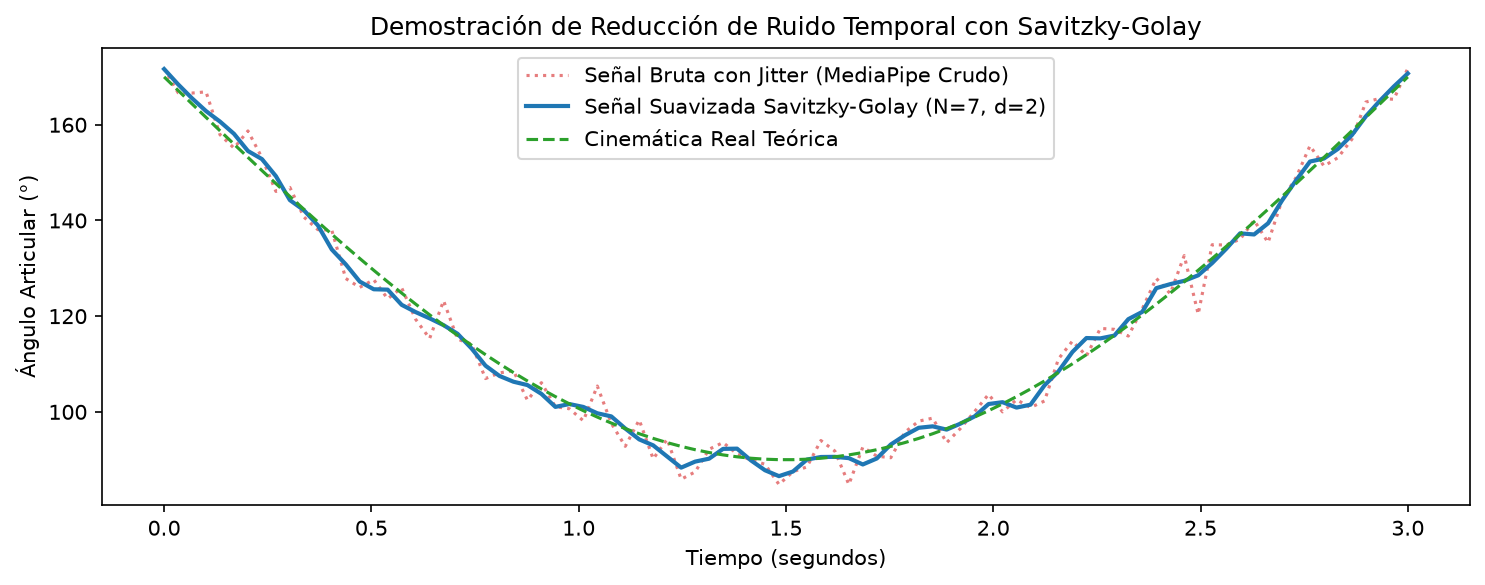

In [2]:
# Demostración del Filtro Temporal Savitzky-Golay sobre Trayectorias
# Simulación de señal cinemática con ruido gausiano de sensor
np.random.seed(42)
time_steps = np.linspace(0, 3.0, 90)
pure_signal = 170.0 - 80.0 * np.sin(np.pi * time_steps / 3.0)  # Trayectoria de flexión de rodilla
noisy_signal = pure_signal + np.random.normal(0, 3.5, size=pure_signal.shape)

# Aplicación del filtro Savitzky-Golay (ventana=7, orden=2)
smoothed_signal = apply_temporal_filter(noisy_signal, window_length=7, polyorder=2)

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4), dpi=150)
plt.plot(time_steps, noisy_signal, label="Señal Bruta con Jitter (MediaPipe Crudo)", color="#d62728", alpha=0.6, linestyle=':')
plt.plot(time_steps, smoothed_signal, label="Señal Suavizada Savitzky-Golay (N=7, d=2)", color="#1f77b4", lw=2)
plt.plot(time_steps, pure_signal, label="Cinemática Real Teórica", color="#2ca02c", linestyle="--")
plt.title("Demostración de Reducción de Ruido Temporal con Savitzky-Golay")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Ángulo Articular (°)")
plt.legend()
plt.tight_layout()
plt.show()


In [3]:
# Carga del dataset cinemático consolidado
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "squat_features.csv")
target_col = 'label' if 'label' in df.columns else 'class_id'

X = df[FEATURE_NAMES].values
y = df[target_col].values
print(f"Matriz de características X: {X.shape}, Vector de etiquetas y: {y.shape}")


Matriz de características X: (10848, 12), Vector de etiquetas y: (10848,)


In [4]:
# Partición Estratificada sin Fuga de Datos (70% Train, 15% Val, 15% Test)
# División inicial: 70% Train, 30% Temporal (Val + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# División del conjunto temporal en 15% Val y 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Muestras de Entrenamiento: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Muestras de Validación:    {len(X_val)} ({len(X_val)/len(X)*100:.1f}%)")
print(f"Muestras de Test Ciego:    {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")


Muestras de Entrenamiento: 7593 (70.0%)
Muestras de Validación:    1627 (15.0%)
Muestras de Test Ciego:    1628 (15.0%)


In [5]:
# Normalización Estándar (Z-Score) Estricta sin Data Leakage
# El scaler se ajusta EXCLUSIVAMENTE sobre X_train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Se transforma X_val y X_test usando los parámetros aprendidos en X_train
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Parámetros del normalizador ajustados:")
print("Medias por feature:", np.round(scaler.mean_, 2))
print("Desviación estándar por feature:", np.round(scaler.scale_, 2))

# Guardado del Scaler
scaler_path = PROJECT_ROOT / "models" / "scaler.pkl"
joblib.dump(scaler, scaler_path)
print(f"[OK] Scaler persistido en: {scaler_path}")


Parámetros del normalizador ajustados:
Medias por feature: [111.13 108.78 115.43 122.06  96.53  97.21  48.33 110.26  22.41  78.89
   0.18   0.7 ]
Desviación estándar por feature: [2.995e+01 3.116e+01 2.801e+01 2.656e+01 3.935e+01 4.126e+01 2.840e+01
 3.221e+01 2.037e+01 9.572e+01 2.000e-01 7.000e-02]
[OK] Scaler persistido en: C:\Users\luis.salgado\Documents\GABO\IA\squat_pose_backend\models\scaler.pkl


### Conclusiones del Preprocesamiento:
1. **Suavizado Temporal:** El filtro Savitzky-Golay preserva los picos de flexión máxima mientras amortigua el ruido oscilatorio de los landmarks.
2. **Normalización Rigurosa:** `StandardScaler` garantiza que variables con escalas dispares (como $knee\_asymmetry\_mm \in [0, 80]$ frente a $valgus\_coeff \in [0, 1.5]$) tengan igual peso en el gradiente de la red.
3. **Paso Siguiente:** Entrenar el modelo base y diagnosticar el sobreajuste en `03_modelado.ipynb`.
